# Часть 2. Исследовательский анализ данных Яндекс Афиши

- Автор: Аргунова Ева
- Дата: 06.08.2026

## Цель и задачи проекта

**Цель** - провести исследовательский анализ данных о бронировании билетов на сервисе Яндекс Афиша, выявить причины изменения пользовательского спроса осенью 2024 года и проверить различия в поведении пользователей мобильных и стационарных устройств.

**Основные задачи:**

- загрузить и изучить исходные данные о заказах, мероприятиях и курсах валют;
- проверить данные на пропуски, дубликаты, некорректные значения и выбросы;
- подготовить данные к исследовательскому анализу;
- изучить изменение количества заказов и средней стоимости билета в летний и осенний периоды;
- определить наиболее популярные типы мероприятий, регионы и билетных операторов;
- проанализировать активность пользователей в осенние месяцы;
- исследовать различия в поведении пользователей мобильных и стационарных устройств;
- проверить статистические гипотезы о различиях между группами пользователей;
- сформулировать итоговые выводы и рекомендации.

## Описание данных

В проекте используются три подготовленных набора данных:

- **final_tickets_orders_df.csv** - информация о заказах билетов с мобильных и стационарных устройств;
- **final_tickets_events_df.csv** - информация о мероприятиях, их типах, регионах, городах и площадках;
- **final_tickets_tenge_df.csv** - ежедневные значения курса тенге к рублю для пересчёта стоимости заказов в единую валюту.

Основной период исследования - с **1 июня по 31 октября 2024 года**.

## Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Проверка статистических гипотез.
5. Общие выводы и рекомендации.

## Загрузка данных и знакомство с ними

На первом этапе загрузим подготовленные наборы данных и проведём их первичное изучение. Проверим размер таблиц, типы данных, наличие пропусков и структуру признаков.

In [1]:
# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ttest_ind

In [2]:
orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
events = pd.read_csv('/datasets/final_tickets_events_df.csv')
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')

### Общая информация о данных

In [3]:
print('Размер таблицы заказов:', orders.shape)
print('Размер таблицы мероприятий:', events.shape)
print('Размер таблицы курса тенге:', tenge.shape)

Размер таблицы заказов: (290849, 14)
Размер таблицы мероприятий: (22427, 11)
Размер таблицы курса тенге: (357, 4)


In [4]:
print('Информация о таблице заказов:')
orders.info()

print('\nИнформация о таблице мероприятий:')
events.info()

print('\nИнформация о таблице курса тенге:')
tenge.info()

Информация о таблице заказов:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: flo

### Первые строки таблиц

In [5]:
display(orders.head())
display(events.head())
display(tenge.head())

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


### Промежуточный вывод

На этапе первичного знакомства были загружены три набора данных: информация о заказах, информация о мероприятиях и ежедневные значения курса казахстанского тенге к российскому рублю.

Таблица заказов содержит **290 849 записей и 14 столбцов**, таблица мероприятий — **22 427 записей и 11 столбцов**, таблица курса валют — **357 записей и 4 столбца**.

Структура и состав столбцов соответствуют описанию данных. В таблицах заказов и мероприятий пропуски отсутствуют, единственный столбец с пропусками — `days_since_prev`. Такие пропуски являются ожидаемыми для пользователей, у которых отсутствует предыдущая покупка.

При этом столбцы с датой и временем в таблицах пока имеют строковый тип. На этапе предобработки потребуется проверить качество данных, типы и значения признаков, дубликаты и выбросы, после чего объединить необходимые данные и подготовить дополнительные признаки для дальнейшего анализа.

### Предварительные предположения о предобработке

По результатам первичного знакомства с данными необходимо будет:

- изучить значения категориальных признаков и проверить их на некорректные или отсутствующие значения;
- проверить распределения количественных признаков, в первую очередь `revenue` и `tickets_count`, и определить наличие выбросов;
- проверить явные и неявные дубликаты заказов;
- преобразовать столбцы с датой и временем в соответствующие типы данных;
- объединить информацию о заказах с данными о мероприятиях и курсах валют;
- привести выручку к единой валюте и создать необходимые для анализа признаки.

## . Предобработка данных и подготовка их к исследованию

На этом этапе проверим качество исходных данных, обработаем пропуски, категориальные и количественные признаки, проверим дубликаты, преобразуем типы данных и подготовим новые признаки для дальнейшего анализа.

###  Проверка пропусков

Проверим наличие пропущенных значений во всех столбцах таблицы заказов. Согласно описанию данных, пропуски допустимы только в столбце `days_since_prev`, поскольку для первой покупки пользователя отсутствует информация о предыдущем заказе.

In [6]:
orders.isna().sum()

order_id                     0
user_id                      0
created_dt_msk               0
created_ts_msk               0
event_id                     0
cinema_circuit               0
age_limit                    0
currency_code                0
device_type_canonical        0
revenue                      0
service_name                 0
tickets_count                0
total                        0
days_since_prev          21940
dtype: int64

### Вывод по пропускам

В таблице заказов пропуски обнаружены только в столбце `days_since_prev` — **21 940 значений**. В остальных столбцах пропущенные значения отсутствуют.

Пропуски в `days_since_prev` являются корректными: они соответствуют заказам пользователей, для которых отсутствует предыдущая покупка. Поэтому заменять или удалять эти значения не требуется.

### Проверка категориальных признаков

Изучим уникальные значения ключевых категориальных признаков. Это позволит выявить возможные ошибки, неявные пропуски и значения, требующие нормализации.

In [7]:
print('Уникальные значения в orders:')
for column in ['currency_code', 'device_type_canonical', 'cinema_circuit', 'service_name', 'age_limit']:
    print(f'\n{column}:')
    print(orders[column].value_counts(dropna=False))

Уникальные значения в orders:

currency_code:
rub    285780
kzt      5069
Name: currency_code, dtype: int64

device_type_canonical:
mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64

cinema_circuit:
нет           289451
Другое          1261
КиноСити         122
Киномакс           7
Москино            7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64

service_name:
Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка            

In [8]:
print('Уникальные значения в events:')
for column in ['event_type_description', 'event_type_main', 'region_name', 'city_name']:
    print(f'\n{column}:')
    print(events[column].value_counts(dropna=False))

Уникальные значения в events:

event_type_description:
концерт                   8485
спектакль                 6015
событие                   4530
шоу                        731
спортивное мероприятие     575
балет                      484
мюзикл                     359
спорт                      297
опера                      252
фестиваль                  212
выставка                   209
ёлка                       157
цирковое шоу               112
экскурсия                    3
подарок                      1
кукольный спектакль          1
музыкальный спектакль        1
рок-мюзикл                   1
оперетта                     1
снегурочка                   1
Name: event_type_description, dtype: int64

event_type_main:
концерты    8680
театр       7076
другое      4658
спорт        872
стендап      636
выставки     290
ёлки         215
Name: event_type_main, dtype: int64

region_name:
Каменевский регион          5983
Североярская область        3814
Широковская область         1

In [9]:
print('Уникальные значения в tenge:')
print('\ncdx:')
print(tenge['cdx'].value_counts(dropna=False))

print('\nnominal:')
print(tenge['nominal'].value_counts(dropna=False))

Уникальные значения в tenge:

cdx:
kzt    357
Name: cdx, dtype: int64

nominal:
100    357
Name: nominal, dtype: int64


### Проверка количественных признаков

Проверим основные количественные признаки и их распределения. В первую очередь рассмотрим `revenue` и `tickets_count`, поскольку они непосредственно характеризуют стоимость заказа и количество приобретённых билетов.

Так как выручка представлена в рублях и тенге, анализ `revenue` проведём отдельно для каждой валюты до пересчёта в российские рубли.

In [10]:
for currency in ['rub', 'kzt']:
    print(f'\nВалюта: {currency.upper()}')
    print(orders.loc[orders['currency_code'] == currency, ['revenue', 'tickets_count']].describe())


Валюта: RUB
             revenue  tickets_count
count  285780.000000  285780.000000
mean      547.568333       2.754077
std       871.524559       1.171419
min       -90.760000       1.000000
25%       113.827500       2.000000
50%       346.100000       3.000000
75%       791.700000       4.000000
max     81174.540000      57.000000

Валюта: KZT
            revenue  tickets_count
count   5069.000000    5069.000000
mean    4995.206767       2.762872
std     4916.752776       1.115558
min        0.000000       1.000000
25%      518.100000       2.000000
50%     3698.830000       3.000000
75%     7397.660000       4.000000
max    26425.860000       6.000000


### Распределение выручки и количества билетов

По статистическим показателям видно, что распределение `revenue` в обеих валютах имеет признаки правосторонней асимметрии: среднее значение выше медианного, а максимальные значения значительно превышают верхний квартиль.

В данных также присутствуют отрицательные значения `revenue` в рублях, которые требуют дополнительной проверки. Для `tickets_count` наблюдаются значения до 57 билетов в одном заказе в рублях и до 6 билетов в тенге.

Для более детальной оценки распределений и выбросов построим гистограммы и диаграммы размаха отдельно для каждой валюты.

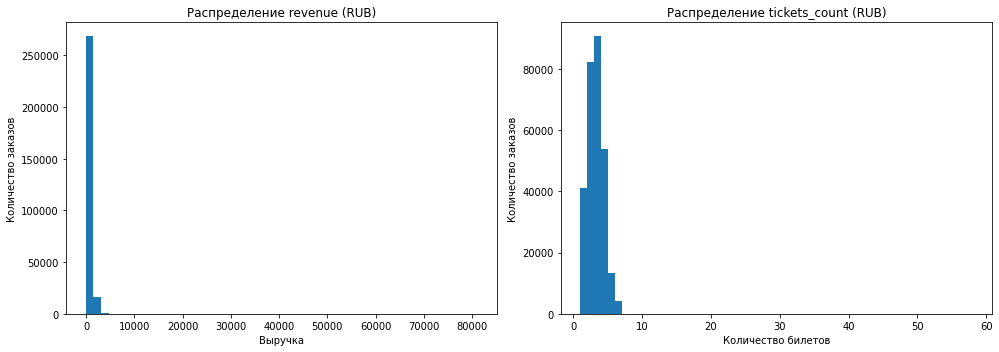

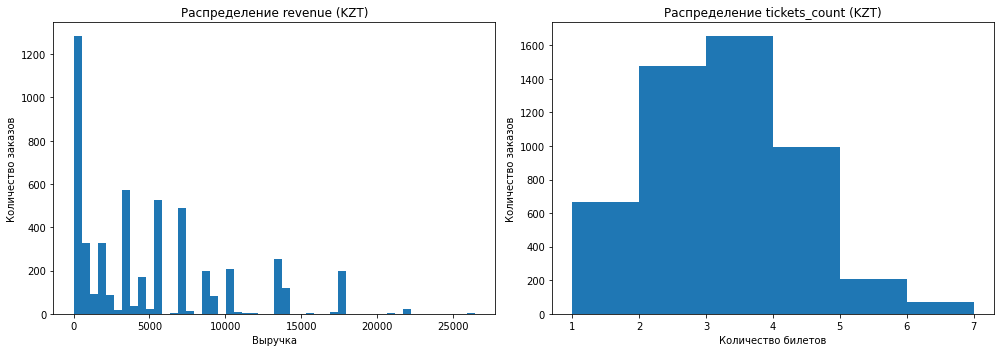

In [11]:
for currency in ['rub', 'kzt']:
    data = orders.loc[orders['currency_code'] == currency]
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].hist(data['revenue'], bins=50)
    axes[0].set_title(f'Распределение revenue ({currency.upper()})')
    axes[0].set_xlabel('Выручка')
    axes[0].set_ylabel('Количество заказов')
    
    axes[1].hist(data['tickets_count'], bins=range(1, data['tickets_count'].max() + 2))
    axes[1].set_title(f'Распределение tickets_count ({currency.upper()})')
    axes[1].set_xlabel('Количество билетов')
    axes[1].set_ylabel('Количество заказов')
    
    plt.tight_layout()
    plt.show()

### Вывод по распределениям

Построение распределений позволило визуально оценить характер данных и выявить возможные выбросы.

По графикам видно, что распределение `revenue` в обеих валютах имеет выраженную правостороннюю асимметрию: основная часть заказов сосредоточена в области небольших значений, при этом присутствуют отдельные заказы с существенно большей выручкой. Особенно заметны экстремальные значения в рублях.

Распределение `tickets_count` в тенге выглядит более компактным и находится в диапазоне от 1 до 6 билетов. В рублёвых заказах также наблюдается основная концентрация значений в небольшом диапазоне, но присутствуют отдельные экстремальные заказы, достигающие 57 билетов.

Таким образом, визуальный анализ подтвердил необходимость дополнительной проверки экстремальных значений. На следующем этапе проверим отрицательные и нулевые значения `revenue`, а также определим 99-й перцентиль отдельно для каждой валюты. Это позволит количественно оценить границу выбросов и принять обоснованное решение о дальнейшей фильтрации данных.

In [12]:
for currency in ['rub', 'kzt']:
    data = orders.loc[orders['currency_code'] == currency, 'revenue']
    
    print(f'\nВалюта: {currency.upper()}')
    print('Количество отрицательных значений:', (data < 0).sum())
    print('Количество нулевых значений:', (data == 0).sum())
    print('99-й перцентиль:', data.quantile(0.99))
    print('Максимальное значение:', data.max())


Валюта: RUB
Количество отрицательных значений: 381
Количество нулевых значений: 5731
99-й перцентиль: 2569.5942000000005
Максимальное значение: 81174.54

Валюта: KZT
Количество отрицательных значений: 0
Количество нулевых значений: 6
99-й перцентиль: 17617.24
Максимальное значение: 26425.86


Выясним природу отрицательных и нулевых значений

In [13]:
print('Отрицательные значения revenue:')
display(
    orders.loc[orders['revenue'] < 0,
               ['order_id', 'user_id', 'created_dt_msk', 'currency_code',
                'revenue', 'tickets_count', 'total', 'service_name']]
    .head(20)
)

print('\nНулевые значения revenue:')
display(
    orders.loc[orders['revenue'] == 0,
               ['order_id', 'user_id', 'created_dt_msk', 'currency_code',
                'revenue', 'tickets_count', 'total', 'service_name']]
    .head(20)
)

Отрицательные значения revenue:


,order_id,user_id,created_dt_msk,currency_code,revenue,tickets_count,total,service_name
264,1594653,00eb3dc9baa1543,2024-06-29,rub,-2.37,3,-59.20,Билеты без проблем
4540,2360920,02ea4583333f064,2024-09-03,rub,-0.23,3,-7.65,Билеты без проблем
4562,2361094,02ea4583333f064,2024-09-04,rub,-0.15,2,-5.10,Билеты без проблем
8155,166809,043f669c9f734b1,2024-09-27,rub,-0.62,1,-20.64,Лучшие билеты
8156,166780,043f669c9f734b1,2024-09-27,rub,-1.86,3,-61.92,Лучшие билеты
11360,6620527,06727636bf2f465,2024-06-30,rub,-1.58,2,-39.46,Билеты без проблем
11361,6620498,06727636bf2f465,2024-07-01,rub,-1.58,2,-52.50,Билеты без проблем
11585,8333963,067494310c6617f,2024-10-07,rub,-6.18,4,-68.72,Билеты в руки
11637,8350029,067494310c6617f,2024-10-24,rub,-10.77,3,-215.31,Билеты в руки
11638,4930755,067494310c6617f,2024-10-24,rub,-3.59,1,-71.77,Билеты в руки



Нулевые значения revenue:


,order_id,user_id,created_dt_msk,currency_code,revenue,tickets_count,total,service_name
24,3253250,0018ecd8a38a51b,2024-07-25,rub,0.0,3,0.0,Билеты без проблем
68,4130442,0033403583a55ed,2024-06-19,rub,0.0,1,0.0,Билеты без проблем
69,4130500,0033403583a55ed,2024-06-19,rub,0.0,1,0.0,Билеты без проблем
70,4130471,0033403583a55ed,2024-06-19,rub,0.0,1,0.0,Билеты без проблем
71,4130529,0033403583a55ed,2024-06-19,rub,0.0,1,0.0,Билеты без проблем
237,8272280,00da083909dc06b,2024-06-07,rub,0.0,4,0.0,Билеты без проблем
238,8272512,00da083909dc06b,2024-06-07,rub,0.0,1,0.0,Билеты без проблем
239,8272251,00da083909dc06b,2024-06-07,rub,0.0,3,0.0,Билеты без проблем
240,8272338,00da083909dc06b,2024-06-07,rub,0.0,2,0.0,Билеты без проблем
241,8272367,00da083909dc06b,2024-06-07,rub,0.0,2,0.0,Билеты без проблем


### Вывод по отрицательным и нулевым значениям

В данных обнаружено **381 отрицательное значение `revenue`**. Все такие значения относятся к рублёвым заказам, при этом `total` также имеет отрицательное значение. Это позволяет предположить, что данные записи могут отражать **возвраты или корректирующие операции**. Поэтому считать их ошибочными и удалять без дополнительного основания не будем.

Также обнаружено **5 731 нулевое значение `revenue` в рублях и 6 — в тенге**. Во всех проверенных примерах `total` также равен нулю, при этом количество билетов может быть больше одного. Вероятно, такие заказы относятся к **билетам с нулевой стоимостью или операциям, не сформировавшим выручку**. Нулевые значения не являются пропусками, поэтому заменять или удалять их также не будем.

Таким образом, отрицательные и нулевые значения сохраняем, а дальнейшую обработку выбросов проведём для аномально высоких значений `revenue`.

Оценим масштаб выбросов перед их фильтрацией

In [14]:
for currency in ['rub', 'kzt']:
    data = orders.loc[orders['currency_code'] == currency, 'revenue']
    p99 = data.quantile(0.99)
    
    print(f'\nВалюта: {currency.upper()}')
    print('99-й перцентиль:', p99)
    print('Количество значений выше 99-го перцентиля:', (data > p99).sum())


Валюта: RUB
99-й перцентиль: 2569.5942000000005
Количество значений выше 99-го перцентиля: 2858

Валюта: KZT
99-й перцентиль: 17617.24
Количество значений выше 99-го перцентиля: 29


### Вывод по экстремальным значениям `revenue`

Проверка показала, что значения выше 99-го перцентиля присутствуют в обеих валютах. Для рублёвых заказов выше порога 2 569,59 находятся 2 858 значений, для заказов в тенге — выше 17 617,24 находятся 29 значений.

Таким образом, экстремальные значения в большей степени характерны для рублёвых заказов. Чтобы они не искажали дальнейший анализ выручки, удалим значения выше 99-го перцентиля отдельно для каждой валюты, поскольку валюты имеют разные масштабы.

In [15]:
p99_rub = orders.loc[orders['currency_code'] == 'rub', 'revenue'].quantile(0.99)
p99_kzt = orders.loc[orders['currency_code'] == 'kzt', 'revenue'].quantile(0.99)

orders_clean = orders[
    ((orders['currency_code'] == 'rub') & (orders['revenue'] <= p99_rub)) |
    ((orders['currency_code'] == 'kzt') & (orders['revenue'] <= p99_kzt))
].copy()

print('Размер исходной таблицы:', orders.shape)
print('Размер таблицы после удаления выбросов:', orders_clean.shape)
print('Удалено строк:', orders.shape[0] - orders_clean.shape[0])

Размер исходной таблицы: (290849, 14)
Размер таблицы после удаления выбросов: (287962, 14)
Удалено строк: 2887


### Вывод по обработке выбросов

Для дальнейшего анализа были исключены заказы с аномально высокой выручкой — значения `revenue` выше 99-го перцентиля отдельно для каждой валюты. В результате из **290 849** исходных заказов удалено **2 887 записей**, что составляет около 1% от общего объёма данных.

После фильтрации осталось **287 962** заказа. Отрицательные и нулевые значения `revenue` при этом сохранены, поскольку они не были признаны ошибочными.

Полученный набор данных `orders_clean` будем использовать для дальнейшей предобработки.

### Проверка дубликатов

In [16]:
print('Количество полных дубликатов:', orders_clean.duplicated().sum())

Количество полных дубликатов: 0


In [17]:
# Проверка неявных дубликатов без учета идентификаторов заказа
duplicate_columns = [
    'user_id',
    'created_dt_msk',
    'created_ts_msk',
    'event_id',
    'cinema_circuit',
    'age_limit',
    'currency_code',
    'device_type_canonical',
    'revenue',
    'service_name',
    'tickets_count',
    'total',
    'days_since_prev'
]

duplicates_implicit = orders_clean[
    orders_clean.duplicated(subset=duplicate_columns, keep=False)
].sort_values(duplicate_columns)

print('Количество строк, участвующих в неявных дубликатах:', len(duplicates_implicit))
print('Количество групп неявных дубликатов:', duplicates_implicit.groupby(duplicate_columns, dropna=False).ngroups)

display(duplicates_implicit.head(20))

Количество строк, участвующих в неявных дубликатах: 58
Количество групп неявных дубликатов: 28


,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
11777,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.0
11778,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,Билеты в руки,1,997.48,0.0
57217,160922,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.0
57220,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,Лови билет!,2,280.81,0.0
84010,3363711,3ee7dc2e115847f,2024-06-25,2024-06-25 07:32:08,277504,нет,6,rub,mobile,59.19,Билеты в руки,3,739.85,0.0
84015,3363798,3ee7dc2e115847f,2024-06-25,2024-06-25 07:32:08,277504,нет,6,rub,mobile,59.19,Билеты в руки,3,739.85,0.0
148473,2324032,7b525118ae656af,2024-10-28,2024-10-28 08:33:04,588203,нет,0,rub,mobile,26.96,Лучшие билеты,4,674.12,0.0
148477,2323916,7b525118ae656af,2024-10-28,2024-10-28 08:33:04,588203,нет,0,rub,mobile,26.96,Лучшие билеты,4,674.12,0.0
154170,5372628,7eb4fc207ecc10f,2024-08-23,2024-08-23 14:08:19,298035,нет,6,rub,mobile,126.84,Билеты без проблем,1,3170.95,0.0
154173,5372831,7eb4fc207ecc10f,2024-08-23,2024-08-23 14:08:19,298035,нет,6,rub,mobile,126.84,Билеты без проблем,1,3170.95,0.0


#### Вывод по  дубликатам

Полных дубликатов в таблице `orders_clean` не обнаружено.

При проверке неявных дубликатов без учёта `order_id` обнаружено **58 строк, объединённых в 28 групп**. В найденных группах совпадают дата и время бронирования, мероприятие, устройство, валюта, выручка, количество билетов и другие характеристики заказа, при этом order_id различается.

Таким образом, записи, вероятно, представляют повторные записи одного и того же бронирования, поэтому их следует считать неявными дубликатами. Для дальнейшего анализа достаточно сохранить по одной записи из каждой группы, чтобы одно бронирование не учитывалось несколько раз.

In [18]:
orders_clean = orders_clean.drop_duplicates(
    subset=duplicate_columns,
    keep='first'
).copy()

print('Количество строк после удаления неявных дубликатов:', len(orders_clean))
print('Удалено строк:', 287962 - len(orders_clean))

Количество строк после удаления неявных дубликатов: 287932
Удалено строк: 30


### Проверка типов данных

In [19]:
orders_clean.dtypes

order_id                   int64
user_id                   object
created_dt_msk            object
created_ts_msk            object
event_id                   int64
cinema_circuit            object
age_limit                  int64
currency_code             object
device_type_canonical     object
revenue                  float64
service_name              object
tickets_count              int64
total                    float64
days_since_prev          float64
dtype: object

In [20]:
# Проверка возможности снижения размерности
numeric_columns = orders_clean.select_dtypes(include='number').columns

orders_clean[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,287932.0,4.327923e+06,2.497644e+06,1.00,2.166294e+06,4328613.50,6490324.25,8653108.00
event_id,287932.0,4.380559e+05,1.474588e+05,4436.00,3.621340e+05,498282.00,546257.00,592325.00
age_limit,287932.0,1.020117e+01,6.526343e+00,0.00,6.000000e+00,12.00,16.00,18.00
revenue,287932.0,5.867184e+02,9.848182e+02,-90.76,1.149675e+02,347.26,793.85,17617.24
tickets_count,287932.0,2.739914e+00,1.162294e+00,1.00,2.000000e+00,3.00,3.00,57.00
total,287932.0,7.194727e+03,1.349055e+04,-358.85,2.132950e+03,4701.39,8826.63,287172.10
days_since_prev,266199.0,3.219975e+00,1.135238e+01,0.00,0.000000e+00,0.00,1.00,148.00


In [21]:
# Приведем даты к корректным типам
orders_clean['created_dt_msk'] = pd.to_datetime(orders_clean['created_dt_msk'])
orders_clean['created_ts_msk'] = pd.to_datetime(orders_clean['created_ts_msk'])

print(orders_clean[['created_dt_msk', 'created_ts_msk']].dtypes)

created_dt_msk    datetime64[ns]
created_ts_msk    datetime64[ns]
dtype: object


### Снижение размерности количественных данных

In [22]:
print('Текущие типы количественных столбцов:')
print(orders_clean[['order_id', 'event_id', 'age_limit',
                    'revenue', 'tickets_count',
                    'total', 'days_since_prev']].dtypes)

print('\nДиапазоны значений:')
print(orders_clean[['order_id', 'event_id', 'age_limit',
                    'tickets_count', 'days_since_prev']].agg(['min', 'max']))

Текущие типы количественных столбцов:
order_id             int64
event_id             int64
age_limit            int64
revenue            float64
tickets_count        int64
total              float64
days_since_prev    float64
dtype: object

Диапазоны значений:
     order_id  event_id  age_limit  tickets_count  days_since_prev
min         1      4436          0              1              0.0
max   8653108    592325         18             57            148.0


In [23]:
orders_clean['age_limit'] = orders_clean['age_limit'].astype('int8')
orders_clean['tickets_count'] = orders_clean['tickets_count'].astype('int8')

print(orders_clean[['age_limit', 'tickets_count']].dtypes)

age_limit        int8
tickets_count    int8
dtype: object


### Вывод по типам данных

Столбцы `created_dt_msk` и `created_ts_msk` были приведены к типу `datetime64[ns]`, что позволит корректно выполнять дальнейший анализ по датам и времени.

Проверка диапазонов количественных признаков показала возможность снизить размерность для `age_limit` и `tickets_count`. Оба столбца переведены из `int64` в `int8`, поскольку максимальные значения составляют соответственно 18 и 57 и полностью помещаются в данный диапазон.

Столбцы `order_id` и `event_id` оставлены в формате `int64`, так как их значения требуют более широкого диапазона. `revenue` и `total` также оставлены в `float64` для сохранения точности денежных расчётов.

`days_since_prev` оставлен в `float64`, поскольку в нём присутствуют пропуски, которые необходимо сохранить.

Таким образом, типы данных приведены к корректному виду, а размерность количественных данных снижена там, где это не приводит к потере информации.

### Приведение выручки к рублям 

In [24]:
print(tenge.dtypes)

data        object
nominal      int64
curs       float64
cdx         object
dtype: object


In [25]:
print('Минимальная дата курса:', tenge['data'].min())
print('Максимальная дата курса:', tenge['data'].max())

Минимальная дата курса: 2024-01-10
Максимальная дата курса: 2024-12-31


In [26]:
tenge['data'] = pd.to_datetime(tenge['data'])

print(tenge['data'].dtype)

datetime64[ns]


In [27]:
print('Количество строк:', len(tenge))
print('Уникальных дат:', tenge['data'].nunique())

Количество строк: 357
Уникальных дат: 357


In [28]:
tenge_rate = tenge[['data', 'curs']].rename(
    columns={'data': 'created_dt_msk', 'curs': 'kzt_to_rub_100'}
)

orders_clean = orders_clean.merge(
    tenge_rate,
    on='created_dt_msk',
    how='left'
)

print('Размер таблицы после объединения:', orders_clean.shape)
print('Пропуски в курсе:', orders_clean['kzt_to_rub_100'].isna().sum())

Размер таблицы после объединения: (287932, 15)
Пропуски в курсе: 0


Создаем столбец `revenue_rub`, перерасчитаем курс по формуле `revenue` * курс / 100

In [29]:
orders_clean['revenue_rub'] = np.where(
    orders_clean['currency_code'] == 'rub',
    orders_clean['revenue'],
    orders_clean['revenue'] * orders_clean['kzt_to_rub_100'] / 100
)

print(orders_clean[['currency_code', 'revenue', 'kzt_to_rub_100', 'revenue_rub']].head(10))

  currency_code  revenue  kzt_to_rub_100  revenue_rub
0           rub  1521.94         18.6972      1521.94
1           rub   289.45         18.3419       289.45
2           rub  1258.57         19.6475      1258.57
3           rub     8.49         18.5010         8.49
4           rub  1390.41         19.6648      1390.41
5           rub   902.74         20.0531       902.74
6           rub   917.83         18.7730       917.83
7           rub    47.78         19.3741        47.78
8           rub    74.84         19.7185        74.84
9           rub  1421.91         18.0419      1421.91


In [30]:
display(
    orders_clean.groupby('currency_code')[['revenue', 'revenue_rub']]
    .agg(['count', 'min', 'max', 'mean'])
)

revenue                               revenue_rub         \
                count    min       max         mean       count    min   
currency_code                                                            
kzt              5040   0.00  17617.24  4893.669063        5040   0.00   
rub            282892 -90.76   2569.59   509.985825      282892 -90.76   

                                        
                       max        mean  
currency_code                           
kzt            3504.562319  961.153603  
rub            2569.590000  509.985825

#### Вывод по приведению выручки к рублям

Для всех заказов была рассчитана единая выручка `revenue_rub` в российских рублях. Для заказов в рублях значение `revenue` было сохранено без изменений, а для заказов в тенге выполнен пересчёт по курсу на дату оформления заказа.

Курс был успешно присоединён ко всем 287 932 заказам, пропущенных значений курса не обнаружено.

После пересчёта значения `revenue_rub` находятся в единой валюте и могут использоваться для дальнейшего анализа выручки независимо от исходной валюты заказа.

### Выручка с продажи одного билета

In [31]:
orders_clean['one_ticket_revenue_rub'] = (
    orders_clean['revenue_rub'] / orders_clean['tickets_count'])

print(
    orders_clean[
        ['revenue_rub', 'tickets_count', 'one_ticket_revenue_rub']
    ].head(10))

   revenue_rub  tickets_count  one_ticket_revenue_rub
0      1521.94              4              380.485000
1       289.45              2              144.725000
2      1258.57              4              314.642500
3         8.49              2                4.245000
4      1390.41              3              463.470000
5       902.74              3              300.913333
6       917.83              4              229.457500
7        47.78              1               47.780000
8        74.84              2               37.420000
9      1421.91              4              355.477500


#### Вывод

На основе `revenue_rub` рассчитан показатель `one_ticket_revenue_rub` — выручка с продажи одного билета на мероприятие. Для каждого заказа выручка в рублях разделена на количество приобретённых билетов `tickets_count`.

### Сезонность 

In [32]:
# Выделим месяц оформления заказа
orders_clean['month'] = orders_clean['created_dt_msk'].dt.month

print(orders_clean[['created_dt_msk', 'month']].head(10))

  created_dt_msk  month
0     2024-08-20      8
1     2024-07-23      7
2     2024-10-06     10
3     2024-07-13      7
4     2024-10-04     10
5     2024-10-23     10
6     2024-08-15      8
7     2024-09-29      9
8     2024-10-15     10
9     2024-06-20      6


In [33]:
# Создадим столбец season и разделим на категории
season_map = {
    1: 'зима',
    2: 'зима',
    3: 'весна',
    4: 'весна',
    5: 'весна',
    6: 'лето',
    7: 'лето',
    8: 'лето',
    9: 'осень',
    10: 'осень',
    11: 'осень',
    12: 'зима'
}

orders_clean['season'] = orders_clean['month'].map(season_map)

print(orders_clean[['month', 'season']].drop_duplicates().sort_values('month'))

   month season
9      6   лето
1      7   лето
0      8   лето
7      9  осень
2     10  осень


In [34]:
# Проверим созданные столбцы
new_columns = [
    'revenue_rub',
    'one_ticket_revenue_rub',
    'month',
    'season'
]

display(orders_clean[new_columns].head(10))

,revenue_rub,one_ticket_revenue_rub,month,season
0,1521.94,380.485000,8,лето
1,289.45,144.725000,7,лето
2,1258.57,314.642500,10,осень
3,8.49,4.245000,7,лето
4,1390.41,463.470000,10,осень
5,902.74,300.913333,10,осень
6,917.83,229.457500,8,лето
7,47.78,47.780000,9,осень
8,74.84,37.420000,10,осень
9,1421.91,355.477500,6,лето


In [35]:
# Распределение заказов по сезонам
print(orders_clean['season'].value_counts())

осень    168607
лето     119325
Name: season, dtype: int64


## Исследовательский анализ данных

### Сезонное распределение заказов

In [36]:
# Кол-во заказов по месяцам
monthly_orders = (
    orders_clean
    .groupby('month')
    .size()
    .reset_index(name='orders_count')
)

display(monthly_orders)

,month,orders_count
0,6,34343
1,7,40410
2,8,44572
3,9,69333
4,10,99274


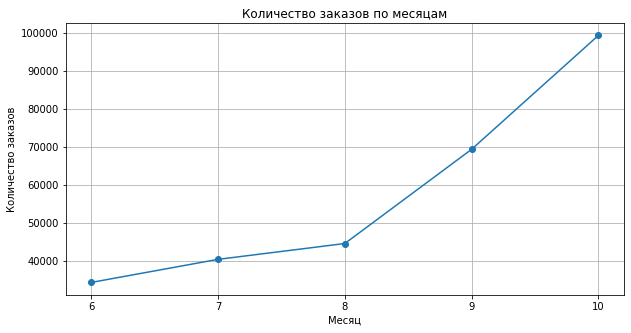

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_orders['month'],
    monthly_orders['orders_count'],
    marker='o'
)

plt.xticks(monthly_orders['month'])
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.title('Количество заказов по месяцам')
plt.grid(True)
plt.show()

In [38]:
season_orders = (
    orders_clean['season']
    .value_counts()
    .reindex(['зима', 'весна', 'лето', 'осень'], fill_value=0)
)

season_share = (season_orders / len(orders_clean) * 100).round(2)

display(
    pd.DataFrame({
        'orders_count': season_orders,
        'share_percent': season_share
    })
)

,orders_count,share_percent
зима,0,0.00
весна,0,0.00
лето,119325,41.44
осень,168607,58.56


### Вывод по динамике заказов

В период с июня по октябрь 2024 года наблюдается устойчивый рост количества заказов. Если в июне было 34 343 заказа, то к октябрю их количество увеличилось до 99 274.

Наибольшее количество заказов приходится на октябрь. Доля заказов осенью составила 58,56%, тогда как летом — 41,44%.

Таким образом, осенью пользователи оформляли заметно больше заказов, чем летом.

### Распределение заказов по категориям

In [39]:
orders_clean = orders_clean.merge(
    events[['event_id', 'event_name', 'event_type_description', 
            'event_type_main', 'organizers', 'region_name', 
            'city_name', 'city_id', 'venue_id', 'venue_name', 
            'venue_address']],
    on='event_id',
    how='left'
)

print('Размер таблицы после объединения:', orders_clean.shape)
print('Пропуски в event_type_main:', orders_clean['event_type_main'].isna().sum())

Размер таблицы после объединения: (287932, 29)
Пропуски в event_type_main: 238


In [40]:
# Проверим пропуски
missing_events = orders_clean.loc[
    orders_clean['event_type_main'].isna(),
    'event_id'
]

print('Количество заказов без информации о мероприятии:', len(missing_events))
print('Количество уникальных event_id:', missing_events.nunique())

display(missing_events.value_counts().head(20))

Количество заказов без информации о мероприятии: 238
Количество уникальных event_id: 19


534151    38
536731    32
532300    27
538260    24
246804    21
555671    20
536716    19
536715    15
530296    15
533222    11
477731     6
559840     3
548224     1
505937     1
572020     1
553041     1
539336     1
553435     1
548062     1
Name: event_id, dtype: int64

In [41]:
# Проверка event_id в исходной таблице events
missing_event_ids = set(missing_events.unique()) - set(events['event_id'].unique())

print('event_id отсутствуют в events:', len(missing_event_ids))
print('Список:', sorted(missing_event_ids))

event_id отсутствуют в events: 19
Список: [246804, 477731, 505937, 530296, 532300, 533222, 534151, 536715, 536716, 536731, 538260, 539336, 548062, 548224, 553041, 553435, 555671, 559840, 572020]


In [42]:
display(
    orders_clean.loc[
        orders_clean['event_type_main'].isna(),
        [
            'order_id',
            'user_id',
            'created_dt_msk',
            'event_id',
            'revenue_rub',
            'tickets_count',
            'service_name'
        ]
    ].head(20)
)

,order_id,user_id,created_dt_msk,event_id,revenue_rub,tickets_count,service_name
62,6493246,002ec276eee9b0b,2024-10-14,533222,78.75,2,Билеты в руки
63,6493275,002ec276eee9b0b,2024-10-14,533222,78.75,2,Билеты в руки
64,6493304,002ec276eee9b0b,2024-10-14,533222,118.12,3,Билеты в руки
234,8272280,00da083909dc06b,2024-06-07,530296,0.00,4,Билеты без проблем
235,8272512,00da083909dc06b,2024-06-07,530296,0.00,1,Билеты без проблем
236,8272251,00da083909dc06b,2024-06-07,530296,0.00,3,Билеты без проблем
237,8272338,00da083909dc06b,2024-06-07,530296,0.00,2,Билеты без проблем
238,8272367,00da083909dc06b,2024-06-07,530296,0.00,2,Билеты без проблем
239,8272396,00da083909dc06b,2024-06-07,530296,0.00,4,Билеты без проблем
240,8272425,00da083909dc06b,2024-06-07,530296,0.00,3,Билеты без проблем


Проверим не являются ли эти 19 мероприятий кинотеатрами, которые были исключены

In [43]:
missing_event_orders = orders_clean[
    orders_clean['event_type_main'].isna()
].copy()

print('Заказы без информации о мероприятии:', len(missing_event_orders))

print('\nРаспределение cinema_circuit:')
print(missing_event_orders['cinema_circuit'].value_counts())

print('\nРаспределение service_name:')
print(missing_event_orders['service_name'].value_counts())

Заказы без информации о мероприятии: 238

Распределение cinema_circuit:
нет    238
Name: cinema_circuit, dtype: int64

Распределение service_name:
Билеты без проблем    190
Лучшие билеты          21
Билеты в руки          21
Мой билет               4
Лови билет!             2
Name: service_name, dtype: int64


In [44]:
display(
    missing_event_orders
    .groupby(['event_id', 'cinema_circuit'])
    .agg(
        orders_count=('order_id', 'count'),
        revenue_rub=('revenue_rub', 'sum')
    )
    .reset_index()
    .sort_values('orders_count', ascending=False)
)

,event_id,cinema_circuit,orders_count,revenue_rub
6,534151,нет,38,0.00
9,536731,нет,32,0.00
4,532300,нет,27,0.00
10,538260,нет,24,0.00
0,246804,нет,21,0.00
16,555671,нет,20,0.00
8,536716,нет,19,0.00
3,530296,нет,15,0.00
7,536715,нет,15,0.00
5,533222,нет,11,1378.07


#### Вывод по объединению

Таблица заказов была объединена с данными о мероприятиях по `event_id`. Количество строк после объединения не изменилось и составило 287 932 заказа.

Для 238 заказов (19 уникальных `event_id`) информация о мероприятии отсутствует в таблице events. Проверка показала, что эти заказы не относятся к кинотеатрам: для всех них `cinema_circuit` = 'нет'.

Поскольку исходные данные не позволяют определить характеристики этих мероприятий, пропуски в `event_type_main` и других связанных признаках заполнять не будем. Сами заказы сохраняем, поскольку они содержат информацию о пользовательской активности и выручке.

In [45]:
# Распределение по типу мероприятия

summer_autumn_events = orders_clean[
    orders_clean['season'].isin(['лето', 'осень']) &
    orders_clean['event_type_main'].notna()
].copy()

event_type_season = pd.crosstab(
    summer_autumn_events['event_type_main'],
    summer_autumn_events['season']
)

event_type_season['лето_%'] = (
    event_type_season['лето'] / event_type_season['лето'].sum() * 100
).round(2)

event_type_season['осень_%'] = (
    event_type_season['осень'] / event_type_season['осень'].sum() * 100
).round(2)

display(event_type_season)

season,лето,осень,лето_%,осень_%
event_type_main,,,,
выставки,2416,2436,2.03,1.44
другое,32369,33225,27.18,19.71
концерты,50757,62694,42.61,37.19
спорт,3006,18881,2.52,11.20
стендап,6346,6923,5.33,4.11
театр,23942,42735,20.10,25.35
ёлки,273,1691,0.23,1.00


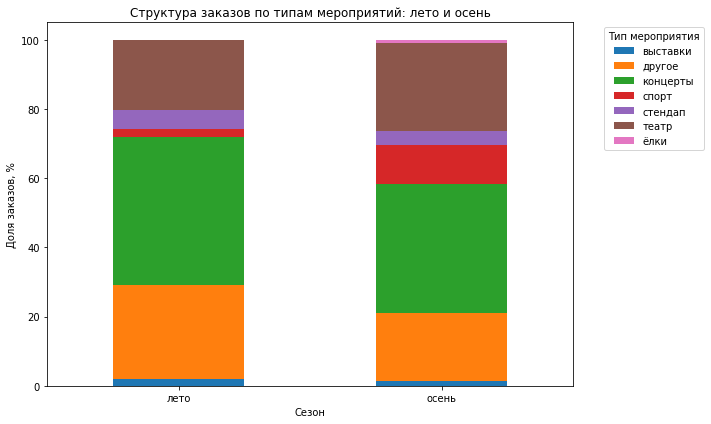

In [46]:
event_type_share = pd.crosstab(
    summer_autumn_events['season'],
    summer_autumn_events['event_type_main'],
    normalize='index'
) * 100

event_type_share.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Структура заказов по типам мероприятий: лето и осень')
plt.xlabel('Сезон')
plt.ylabel('Доля заказов, %')
plt.xticks(rotation=0)
plt.legend(title='Тип мероприятия', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [47]:
# Распределение по типу устройства

device_season = pd.crosstab(
    summer_autumn_events['device_type_canonical'],
    summer_autumn_events['season']
)

device_season['лето_%'] = (
    device_season['лето'] / device_season['лето'].sum() * 100
).round(2)

device_season['осень_%'] = (
    device_season['осень'] / device_season['осень'].sum() * 100
).round(2)

display(device_season)

season,лето,осень,лето_%,осень_%
device_type_canonical,,,,
desktop,23058,34299,19.36,20.35
mobile,96051,134286,80.64,79.65


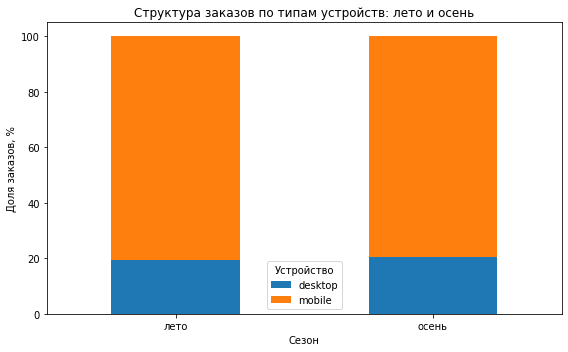

In [48]:
device_share = pd.crosstab(
    summer_autumn_events['season'],
    summer_autumn_events['device_type_canonical'],
    normalize='index'
) * 100

device_share.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Структура заказов по типам устройств: лето и осень')
plt.xlabel('Сезон')
plt.ylabel('Доля заказов, %')
plt.xticks(rotation=0)
plt.legend(title='Устройство')
plt.tight_layout()
plt.show()

In [49]:
# Распределение по возрастному ограничению

age_season = pd.crosstab(
    summer_autumn_events['age_limit'],
    summer_autumn_events['season']
)

age_season['лето_%'] = (
    age_season['лето'] / age_season['лето'].sum() * 100
).round(2)

age_season['осень_%'] = (
    age_season['осень'] / age_season['осень'].sum() * 100
).round(2)

display(age_season)

season,лето,осень,лето_%,осень_%
age_limit,,,,
0,21404,39828,17.97,23.62
6,21672,29720,18.20,17.63
12,24453,37217,20.53,22.08
16,33756,44217,28.34,26.23
18,17824,17603,14.96,10.44


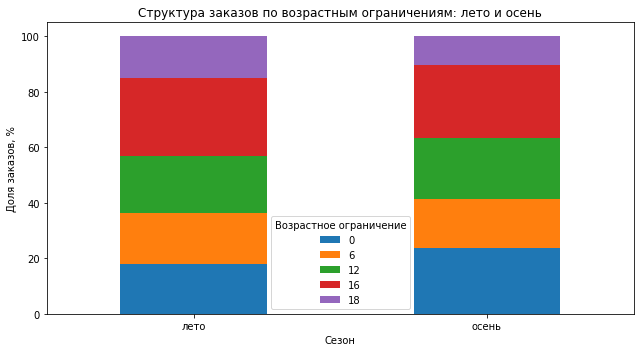

In [50]:
age_share = pd.crosstab(
    summer_autumn_events['season'],
    summer_autumn_events['age_limit'],
    normalize='index'
) * 100

age_share.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Структура заказов по возрастным ограничениям: лето и осень')
plt.xlabel('Сезон')
plt.ylabel('Доля заказов, %')
plt.xticks(rotation=0)
plt.legend(title='Возрастное ограничение')
plt.tight_layout()
plt.show()

#### Средняя стоимость одного билета по типам мероприятий

In [51]:
avg_ticket_revenue = (
    summer_autumn_events
    .groupby(['event_type_main', 'season'])['one_ticket_revenue_rub']
    .mean()
    .unstack()
)

avg_ticket_revenue['change_%'] = (
    (avg_ticket_revenue['осень'] - avg_ticket_revenue['лето'])
    / avg_ticket_revenue['лето'] * 100
).round(2)

avg_ticket_revenue = avg_ticket_revenue.round(2)

display(avg_ticket_revenue)

season,лето,осень,change_%
event_type_main,,,
выставки,86.42,90.60,4.85
другое,77.43,76.12,-1.70
концерты,304.72,268.08,-12.02
спорт,50.76,49.97,-1.56
стендап,218.52,231.12,5.77
театр,214.13,175.97,-17.82
ёлки,271.44,229.59,-15.42


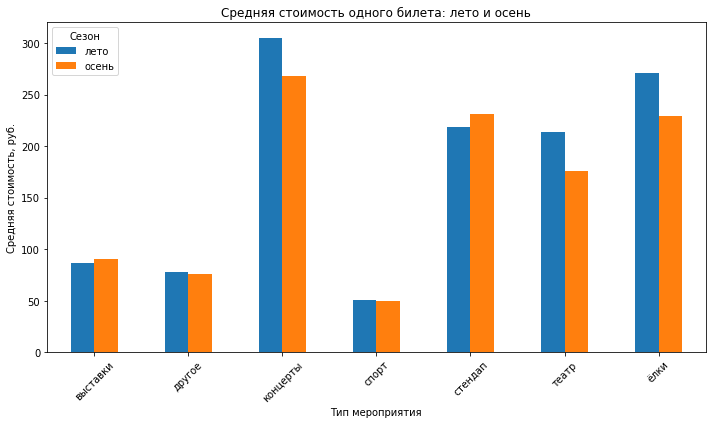

In [52]:
avg_ticket_revenue[['лето', 'осень']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Средняя стоимость одного билета: лето и осень')
plt.xlabel('Тип мероприятия')
plt.ylabel('Средняя стоимость, руб.')
plt.xticks(rotation=45)
plt.legend(title='Сезон')
plt.tight_layout()
plt.show()

#### Вывод по распределению заказов

С наступлением осени структура заказов по типам мероприятий заметно изменилась. Доля заказов на концерты осталась самой высокой, но снизилась с 42,61% до 37,19%. Также уменьшилась доля категории «другое» — с 27,18% до 19,71%, и стендапа — с 5,33% до 4,11%.

При этом значительно выросла доля заказов на спорт — с 2,52% до 11,20%, а также на театр — с 20,10% до 25,35%. Увеличилась и доля заказов на ёлки — с 0,23% до 1,00%, что соответствует началу подготовки к зимнему сезону. Доля выставок немного снизилась — с 2,03% до 1,44%.

По типу устройства распределение практически не изменилось: около 80% заказов приходится на мобильные устройства, а около 20% — на компьютеры.

По возрастным ограничениям заметно снижение доли заказов на мероприятия 18+ — с 15,04% до 10,44%, при этом выросла доля мероприятий без возрастного ограничения — с 17,94% до 23,62%. Остальные категории изменились незначительно.

#### Изменение средней стоимости одного билета

Средняя стоимость одного билета изменилась по всем типам мероприятий:

- выставки: +4,85%;
- стендап: +5,77%;
- концерты: −12,02%;
- театр: −17,82%;
- ёлки: −15,42%;
- спорт: −1,56%;
- другое: −1,70%.

Таким образом, осенью билеты на **выставки и стендап немного подорожали**, тогда как для остальных типов мероприятий средняя стоимость снизилась. Наиболее заметное снижение наблюдается у **театра — на 17,82%**, концертов — на 12,02% и ёлок — на 15,42%.

С наступлением осени меняется не только количество заказов, но и их структура: возрастает интерес к спортивным и театральным мероприятиям, тогда как относительная доля концертов и категории «другое» снижается. При этом пользователи по-прежнему преимущественно оформляют заказы с мобильных устройств. Средняя стоимость билета осенью в большинстве категорий снизилась, несмотря на рост общего количества заказов.

### Осенняя активность пользователей

Проанализируем активность пользователей в сентябре и октябре 2024 года. Для каждого дня рассчитаем:
- общее количество заказов;
- количество уникальных активных пользователей (DAU);
- среднее количество заказов на одного пользователя;
- среднюю стоимость одного билета.

После этого изучим недельную цикличность и сравним активность пользователей в будни и выходные дни.

In [53]:
autumn = orders_clean[
    orders_clean['season'] == 'осень'
].copy()

print('Количество заказов осенью:', len(autumn))
print('Период:', autumn['created_dt_msk'].min().date(), '—', autumn['created_dt_msk'].max().date())

Количество заказов осенью: 168607
Период: 2024-09-01 — 2024-10-31


In [54]:
# Сводная таблица по дням

daily_activity = (
    autumn
    .groupby('created_dt_msk')
    .agg(
        orders_count=('order_id', 'count'),
        dau=('user_id', 'nunique'),
        avg_orders_per_user=('order_id', lambda x: x.count() / autumn.loc[x.index, 'user_id'].nunique()),
        avg_ticket_revenue_rub=('one_ticket_revenue_rub', 'mean')).reset_index())

display(daily_activity.head(10))

,created_dt_msk,orders_count,dau,avg_orders_per_user,avg_ticket_revenue_rub
0,2024-09-01,1327,564,2.352837,200.168708
1,2024-09-02,1380,574,2.404181,189.464639
2,2024-09-03,5111,778,6.569409,80.130097
3,2024-09-04,1773,685,2.588321,177.685576
4,2024-09-05,1944,739,2.630582,189.510156
5,2024-09-06,2125,864,2.459491,174.787297
6,2024-09-07,1959,794,2.467254,190.144186
7,2024-09-08,1713,717,2.389121,181.973169
8,2024-09-09,2094,779,2.688062,159.346506
9,2024-09-10,2020,762,2.650919,183.145535


In [55]:
# Проверим диапозон

print('Количество дней:', len(daily_activity))
print('Первый день:', daily_activity['created_dt_msk'].min().date())
print('Последний день:', daily_activity['created_dt_msk'].max().date())

Количество дней: 61
Первый день: 2024-09-01
Последний день: 2024-10-31


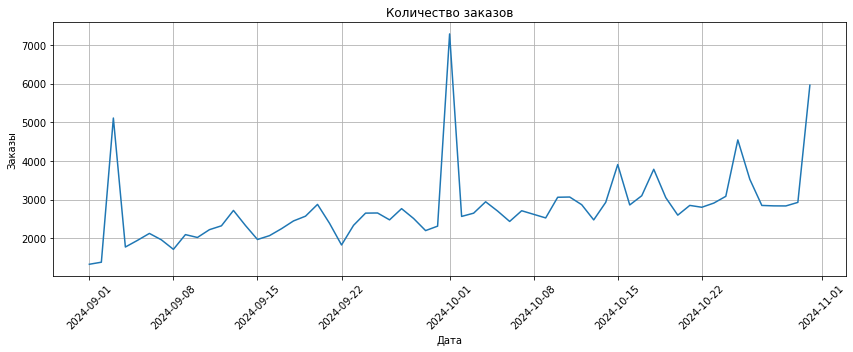

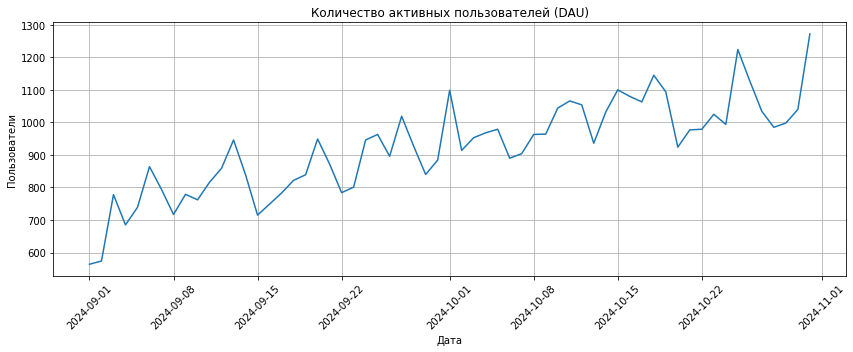

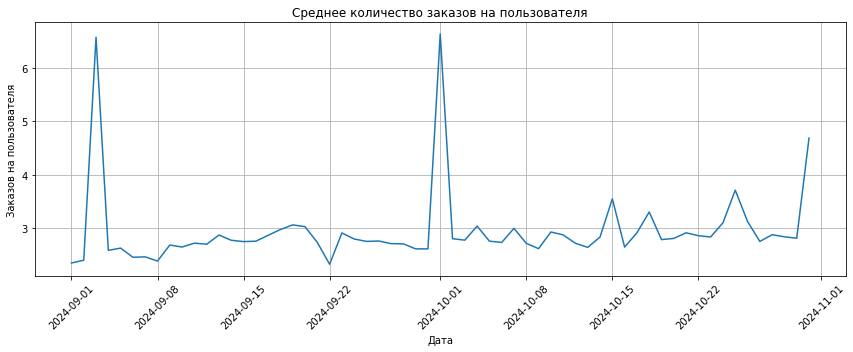

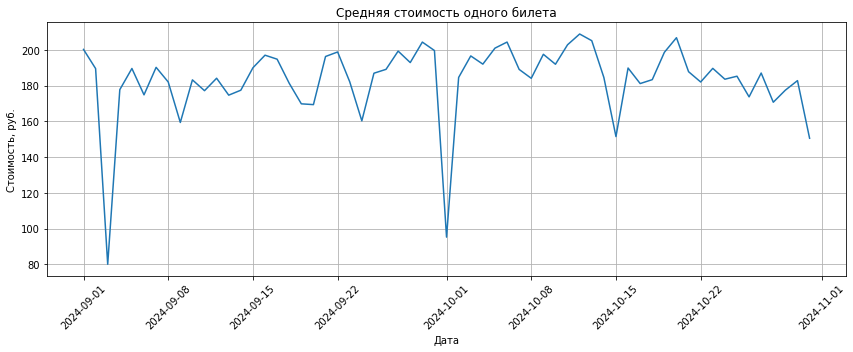

In [56]:
# Визуализация динамики по дням
# 4 отдельных графика 

metrics = {
    'orders_count': ('Количество заказов', 'Заказы'),
    'dau': ('Количество активных пользователей (DAU)', 'Пользователи'),
    'avg_orders_per_user': ('Среднее количество заказов на пользователя', 'Заказов на пользователя'),
    'avg_ticket_revenue_rub': ('Средняя стоимость одного билета', 'Стоимость, руб.')
}

for column, (title, ylabel) in metrics.items():
    plt.figure(figsize=(12, 5))
    plt.plot(
        daily_activity['created_dt_msk'],
        daily_activity[column]
    )
    plt.title(title)
    plt.xlabel('Дата')
    plt.ylabel(ylabel)
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

#### Недельная цикличность

In [57]:
daily_activity['weekday'] = daily_activity['created_dt_msk'].dt.dayofweek

weekday_names = {
    0: 'Понедельник',
    1: 'Вторник',
    2: 'Среда',
    3: 'Четверг',
    4: 'Пятница',
    5: 'Суббота',
    6: 'Воскресенье'
}

daily_activity['weekday_name'] = daily_activity['weekday'].map(weekday_names)

In [58]:
weekday_activity = (
    daily_activity
    .groupby(['weekday', 'weekday_name'])
    [['orders_count', 'dau', 'avg_orders_per_user', 'avg_ticket_revenue_rub']]
    .mean()
    .reset_index()
    .sort_values('weekday')
)

weekday_activity = weekday_activity.round(2)

display(weekday_activity)

,weekday,weekday_name,orders_count,dau,avg_orders_per_user,avg_ticket_revenue_rub
0,0,Понедельник,2390.78,853.89,2.78,184.36
1,1,Вторник,3497.78,934.22,3.72,156.49
2,2,Среда,2543.11,923.22,2.75,185.21
3,3,Четверг,3018.78,962.11,3.06,181.77
4,4,Пятница,3103.50,1022.62,3.00,185.14
5,5,Суббота,2667.00,960.75,2.76,192.30
6,6,Воскресенье,2154.33,822.67,2.60,197.56


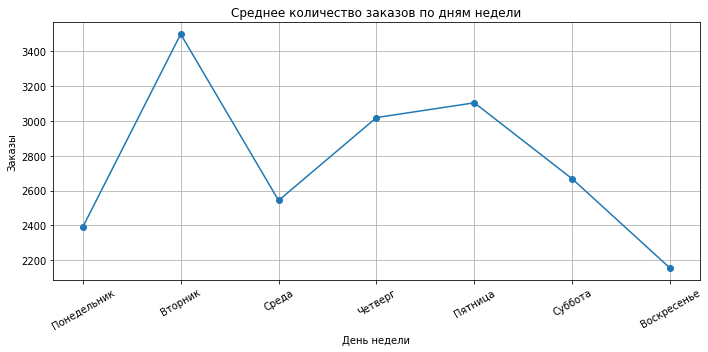

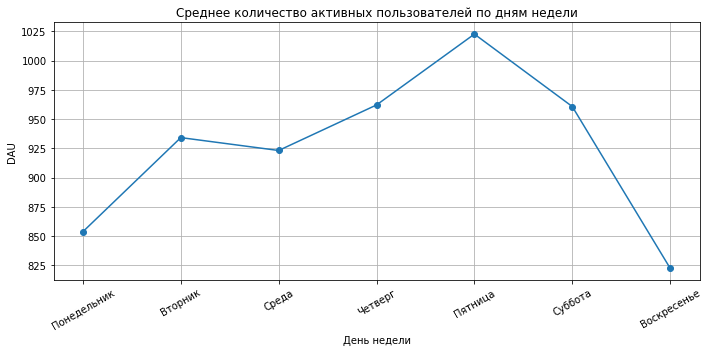

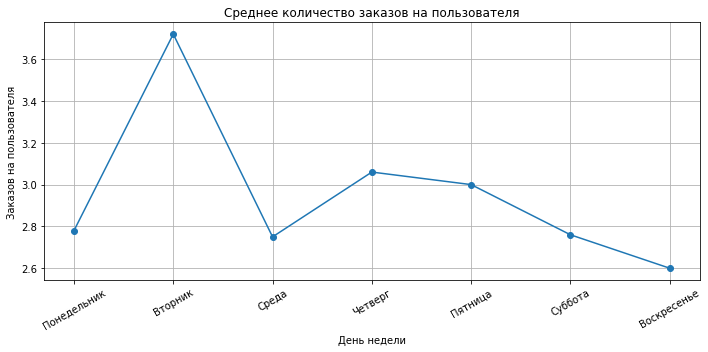

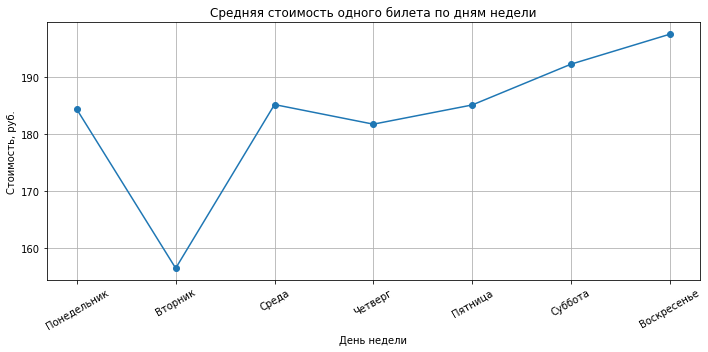

In [59]:
metrics = {
    'orders_count': ('Среднее количество заказов по дням недели', 'Заказы'),
    'dau': ('Среднее количество активных пользователей по дням недели', 'DAU'),
    'avg_orders_per_user': ('Среднее количество заказов на пользователя', 'Заказов на пользователя'),
    'avg_ticket_revenue_rub': ('Средняя стоимость одного билета по дням недели', 'Стоимость, руб.')
}

for column, (title, ylabel) in metrics.items():
    plt.figure(figsize=(10, 5))
    plt.plot(
        weekday_activity['weekday_name'],
        weekday_activity[column],
        marker='o'
    )
    plt.title(title)
    plt.xlabel('День недели')
    plt.ylabel(ylabel)
    plt.xticks(rotation=30)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [60]:
# Сравниваем будни и выходные

daily_activity['day_type'] = np.where(
    daily_activity['weekday'] < 5,
    'Будни',
    'Выходные'
)

weekday_vs_weekend = (
    daily_activity
    .groupby('day_type')
    [['orders_count', 'dau', 'avg_orders_per_user', 'avg_ticket_revenue_rub']] # Средние значения 
    .mean()
    .round(2)
)

display(weekday_vs_weekend)

,orders_count,dau,avg_orders_per_user,avg_ticket_revenue_rub
day_type,,,,
Будни,2906.41,937.32,3.07,178.44
Выходные,2395.59,887.65,2.68,195.08


In [61]:
weekday_vs_weekend_change = pd.DataFrame({
    'Будни': weekday_vs_weekend.loc['Будни'],
    'Выходные': weekday_vs_weekend.loc['Выходные']
})

weekday_vs_weekend_change['Изменение_%'] = (
    (weekday_vs_weekend_change['Выходные'] -
     weekday_vs_weekend_change['Будни'])
    / weekday_vs_weekend_change['Будни'] * 100 # Прцентное изменение
).round(2)

display(weekday_vs_weekend_change)

,Будни,Выходные,Изменение_%
orders_count,2906.41,2395.59,-17.58
dau,937.32,887.65,-5.30
avg_orders_per_user,3.07,2.68,-12.70
avg_ticket_revenue_rub,178.44,195.08,9.33


#### Промежуточный вывод по пользовательской активности и недельной цикличности

В течение сентября и октября 2024 года пользовательская активность заметно менялась от дня к дню. Количество заказов и среднее число заказов на одного пользователя имели отдельные выраженные всплески, особенно 1 сентября и 1 октября. Минимальная активность по количеству заказов наблюдалась 8 сентября, а по среднему числу заказов на пользователя — 8 и 22 сентября. DAU в целом увеличивался к концу октября. Средняя стоимость одного билета также менялась: наиболее высокие значения наблюдались примерно в середине октября, а более низкие — в начале сентября и 1 октября.

Наблюдается выраженная недельная цикличность. В будни в среднем оформлялось 2 906 заказов в день, тогда как в выходные — 2 396, то есть на 17,58% меньше. Среднее количество активных пользователей также было ниже в выходные — на 5,30%. При этом среднее количество заказов на одного пользователя снижалось с 3,07 до 2,68 (−12,70%).

Интересно, что несмотря на меньшую активность пользователей, средняя стоимость одного билета в выходные была выше: 195,08 руб. против 178,44 руб. в будни, то есть на 9,33%.

В целом: осенью пользователи были активнее в будние дни — в это время больше и заказов, и активных пользователей, и заказов в расчёте на пользователя. В выходные активность снижалась, но средняя стоимость приобретаемого билета была выше.

### Популярные события и партнёры

Проанализируем распределение мероприятий и заказов по регионам, а также активность билетных партнёров осенью 2024 года.

Для регионов определим количество уникальных мероприятий и общее число заказов. Для билетных партнёров рассчитаем количество уникальных мероприятий, число обработанных заказов и суммарную выручку. Помимо абсолютных значений, рассмотрим долю каждого региона и партнёра в общем объёме.

In [62]:
autumn_region = (
    autumn[autumn['region_name'].notna()]
    .groupby('region_name')
    .agg(
        unique_events=('event_id', 'nunique'),
        orders_count=('order_id', 'count'),
        revenue_rub=('revenue_rub', 'sum')
    )
    .reset_index()
)

autumn_region['events_share_%'] = (
    autumn_region['unique_events']
    / autumn_region['unique_events'].sum() * 100
).round(2)

autumn_region['orders_share_%'] = (
    autumn_region['orders_count']
    / autumn_region['orders_count'].sum() * 100
).round(2)

autumn_region['revenue_share_%'] = (
    autumn_region['revenue_rub']
    / autumn_region['revenue_rub'].sum() * 100
).round(2)

autumn_region = autumn_region.sort_values(
    'unique_events',
    ascending=False
)

display(autumn_region.head(20))

,region_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
23,Каменевский регион,3910,46684,2.860734e+07,24.63,27.69,34.98
59,Североярская область,2613,20718,1.053250e+07,16.46,12.29,12.88
75,Широковская область,803,8715,4.227784e+06,5.06,5.17,5.17
56,Светополянский округ,764,4779,1.987402e+06,4.81,2.83,2.43
51,Речиновская область,529,3565,1.740919e+06,3.33,2.11,2.13
60,Серебринская область,456,4467,1.562719e+06,2.87,2.65,1.91
76,Яблоневская область,432,4199,1.943528e+06,2.72,2.49,2.38
67,Тепляковская область,419,2485,7.701039e+05,2.64,1.47,0.94
11,Горицветская область,406,3230,1.114419e+06,2.56,1.92,1.36
63,Солнечноземская область,403,4228,8.627110e+05,2.54,2.51,1.06


In [63]:
# Посмотрим регионы-лидеры по заказам
display(
    autumn_region
    .sort_values('orders_count', ascending=False)
    .head(20)
)


,region_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
23,Каменевский регион,3910,46684,2.860734e+07,24.63,27.69,34.98
59,Североярская область,2613,20718,1.053250e+07,16.46,12.29,12.88
41,Медовская область,369,12044,2.343986e+06,2.32,7.14,2.87
75,Широковская область,803,8715,4.227784e+06,5.06,5.17,5.17
44,Озернинский край,296,7480,6.632991e+06,1.86,4.44,8.11
56,Светополянский округ,764,4779,1.987402e+06,4.81,2.83,2.43
60,Серебринская область,456,4467,1.562719e+06,2.87,2.65,1.91
40,Малиновоярский округ,137,4412,3.365825e+06,0.86,2.62,4.12
63,Солнечноземская область,403,4228,8.627110e+05,2.54,2.51,1.06
76,Яблоневская область,432,4199,1.943528e+06,2.72,2.49,2.38


In [64]:
# Посмотрим регионы-лидеры по выручке
display(
    autumn_region
    .sort_values('revenue_rub', ascending=False)
    .head(20)
)

,region_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
23,Каменевский регион,3910,46684,2.860734e+07,24.63,27.69,34.98
59,Североярская область,2613,20718,1.053250e+07,16.46,12.29,12.88
44,Озернинский край,296,7480,6.632991e+06,1.86,4.44,8.11
75,Широковская область,803,8715,4.227784e+06,5.06,5.17,5.17
40,Малиновоярский округ,137,4412,3.365825e+06,0.86,2.62,4.12
41,Медовская область,369,12044,2.343986e+06,2.32,7.14,2.87
56,Светополянский округ,764,4779,1.987402e+06,4.81,2.83,2.43
76,Яблоневская область,432,4199,1.943528e+06,2.72,2.49,2.38
51,Речиновская область,529,3565,1.740919e+06,3.33,2.11,2.13
38,Лугоградская область,182,2986,1.610895e+06,1.15,1.77,1.97


**Визуализация регионов**

Чтобы не строить огромный график по всем 81 регионам, возьмём топ-10 регионов по количеству уникальных мероприятий:

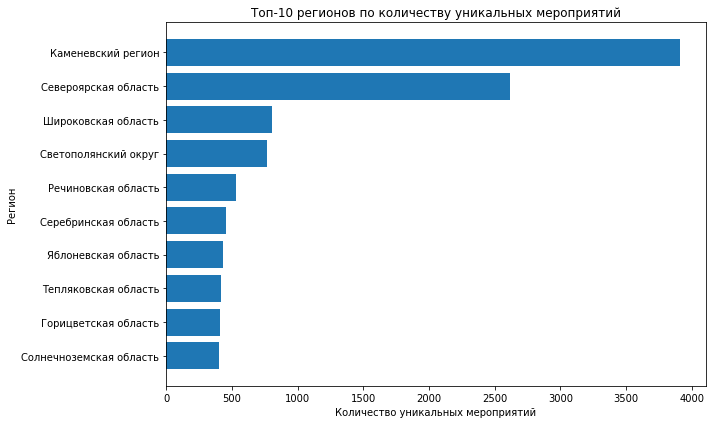

In [65]:
top_regions = (
    autumn_region
    .sort_values('unique_events', ascending=False)
    .head(10)
    .sort_values('unique_events')
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_regions['region_name'],
    top_regions['unique_events']
)
plt.title('Топ-10 регионов по количеству уникальных мероприятий')
plt.xlabel('Количество уникальных мероприятий')
plt.ylabel('Регион')
plt.tight_layout()
plt.show()

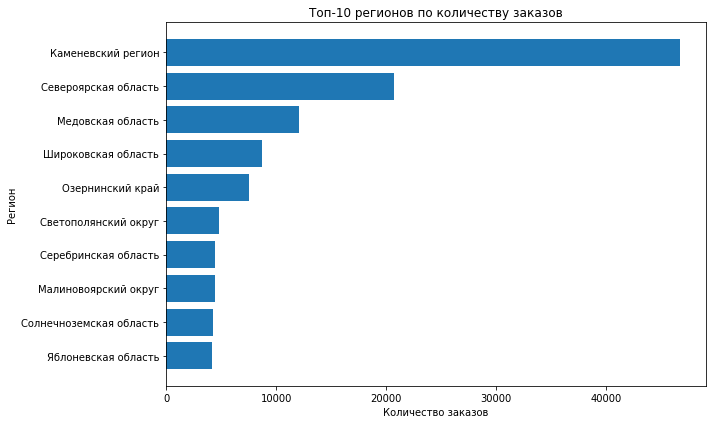

In [66]:
# Топ-10 по заказам
top_regions_orders = (
    autumn_region
    .sort_values('orders_count', ascending=False)
    .head(10)
    .sort_values('orders_count')
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_regions_orders['region_name'],
    top_regions_orders['orders_count']
)
plt.title('Топ-10 регионов по количеству заказов')
plt.xlabel('Количество заказов')
plt.ylabel('Регион')
plt.tight_layout()
plt.show()

#### Билетные партнеры

In [67]:
autumn_partners = (
    autumn
    .groupby('service_name')
    .agg(
        unique_events=('event_id', 'nunique'),
        orders_count=('order_id', 'count'),
        revenue_rub=('revenue_rub', 'sum')
    )
    .reset_index()
)

autumn_partners['events_share_%'] = (
    autumn_partners['unique_events']
    / autumn_partners['unique_events'].sum() * 100
).round(2)

autumn_partners['orders_share_%'] = (
    autumn_partners['orders_count']
    / autumn_partners['orders_count'].sum() * 100
).round(2)

autumn_partners['revenue_share_%'] = (
    autumn_partners['revenue_rub']
    / autumn_partners['revenue_rub'].sum() * 100
).round(2)

autumn_partners.head(20)

,service_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
0,Crazy ticket!,178,550,3.194516e+05,1.03,0.33,0.39
1,Show_ticket,204,1300,9.061671e+05,1.18,0.77,1.11
2,Билет по телефону,10,50,3.780782e+04,0.06,0.03,0.05
3,Билеты без проблем,2847,32383,1.211601e+07,16.45,19.21,14.82
4,Билеты в интернете,1,4,5.482300e+02,0.01,0.00,0.00
5,Билеты в руки,2471,25734,7.613966e+06,14.28,15.26,9.31
6,Быстробилет,133,1162,9.294932e+05,0.77,0.69,1.14
7,Быстрый кассир,1,8,7.780710e+03,0.01,0.00,0.01
8,Весь в билетах,599,9406,9.325571e+06,3.46,5.58,11.40
9,Восьмёрка,92,390,2.384224e+05,0.53,0.23,0.29


In [68]:
# По кол-ву мероприятий
display(
    autumn_partners
    .sort_values('unique_events', ascending=False)
)

,service_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
21,Лови билет!,3616,25792,1.037679e+07,20.90,15.30,12.69
3,Билеты без проблем,2847,32383,1.211601e+07,16.45,19.21,14.82
5,Билеты в руки,2471,25734,7.613966e+06,14.28,15.26,9.31
25,Облачко,1409,15478,1.061105e+07,8.14,9.18,12.98
22,Лучшие билеты,1397,12445,1.676010e+06,8.07,7.38,2.05
24,Мой билет,1006,19419,1.085081e+07,5.81,11.52,13.27
30,Тебе билет!,859,3749,2.137900e+06,4.96,2.22,2.61
26,Прачечная,728,5798,2.548310e+06,4.21,3.44,3.12
8,Весь в билетах,599,9406,9.325571e+06,3.46,5.58,11.40
34,Яблоко,537,3473,2.763332e+06,3.10,2.06,3.38


In [69]:
# По кол-ву заказов
display(
    autumn_partners
    .sort_values('orders_count', ascending=False)
)

,service_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
3,Билеты без проблем,2847,32383,1.211601e+07,16.45,19.21,14.82
21,Лови билет!,3616,25792,1.037679e+07,20.90,15.30,12.69
5,Билеты в руки,2471,25734,7.613966e+06,14.28,15.26,9.31
24,Мой билет,1006,19419,1.085081e+07,5.81,11.52,13.27
25,Облачко,1409,15478,1.061105e+07,8.14,9.18,12.98
22,Лучшие билеты,1397,12445,1.676010e+06,8.07,7.38,2.05
8,Весь в билетах,599,9406,9.325571e+06,3.46,5.58,11.40
26,Прачечная,728,5798,2.548310e+06,4.21,3.44,3.12
30,Тебе билет!,859,3749,2.137900e+06,4.96,2.22,2.61
34,Яблоко,537,3473,2.763332e+06,3.10,2.06,3.38


In [70]:
# По выручке
display(
    autumn_partners
    .sort_values('revenue_rub', ascending=False)
)

,service_name,unique_events,orders_count,revenue_rub,events_share_%,orders_share_%,revenue_share_%
3,Билеты без проблем,2847,32383,1.211601e+07,16.45,19.21,14.82
24,Мой билет,1006,19419,1.085081e+07,5.81,11.52,13.27
25,Облачко,1409,15478,1.061105e+07,8.14,9.18,12.98
21,Лови билет!,3616,25792,1.037679e+07,20.90,15.30,12.69
8,Весь в билетах,599,9406,9.325571e+06,3.46,5.58,11.40
5,Билеты в руки,2471,25734,7.613966e+06,14.28,15.26,9.31
19,Край билетов,193,2997,3.018373e+06,1.12,1.78,3.69
34,Яблоко,537,3473,2.763332e+06,3.10,2.06,3.38
26,Прачечная,728,5798,2.548310e+06,4.21,3.44,3.12
30,Тебе билет!,859,3749,2.137900e+06,4.96,2.22,2.61


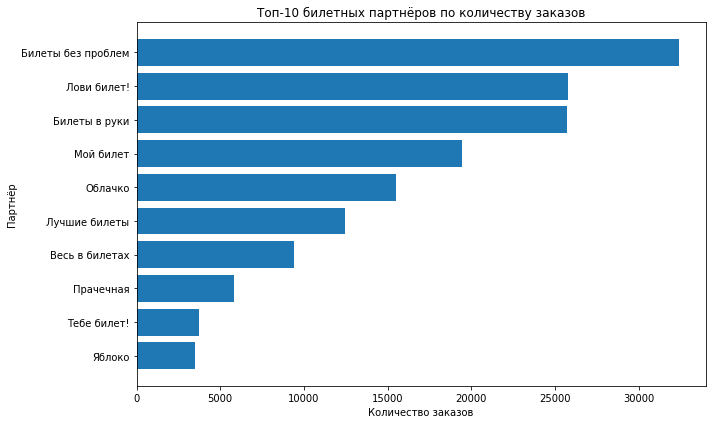

In [71]:
# Визуализация топ-10 по заказам
top_partners_orders = (
    autumn_partners
    .sort_values('orders_count', ascending=False)
    .head(10)
    .sort_values('orders_count')
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_partners_orders['service_name'],
    top_partners_orders['orders_count']
)
plt.title('Топ-10 билетных партнёров по количеству заказов')
plt.xlabel('Количество заказов')
plt.ylabel('Партнёр')
plt.tight_layout()
plt.show()

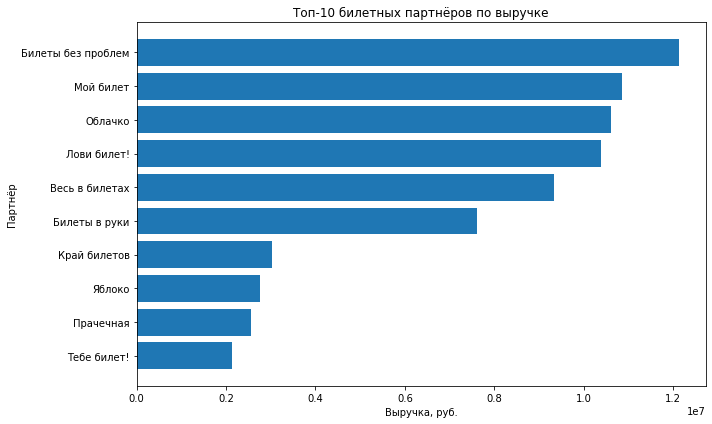

In [72]:
# Визуализация топ-10 по выручке
top_partners_revenue = (
    autumn_partners
    .sort_values('revenue_rub', ascending=False)
    .head(10)
    .sort_values('revenue_rub')
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_partners_revenue['service_name'],
    top_partners_revenue['revenue_rub']
)
plt.title('Топ-10 билетных партнёров по выручке')
plt.xlabel('Выручка, руб.')
plt.ylabel('Партнёр')
plt.tight_layout()
plt.show()

#### Промежуточный вывод

Осенью 2024 года распределение мероприятий по регионам было неравномерным. Явным лидером по разнообразию мероприятий является **Каменевский регион** — 3 910 уникальных мероприятий, или 24,63% от общего количества. На втором месте находится **Североярская область** — 2 613 мероприятий (16,46%). Далее идёт Широковская область — 803 мероприятия (5,06%). Таким образом, уже первые два региона значительно опережают остальные по представленному разнообразию мероприятий.

По количеству заказов лидируют те же регионы: на Каменевский регион приходится **46 684 заказа (27,69%)**, на Североярскую область — 20 718 (12,29%). При этом заметный объём заказов наблюдается и в Медовской области — 12 044 заказа (7,14%), несмотря на сравнительно небольшое количество уникальных мероприятий — 369. Это говорит о том, что высокая популярность региона не всегда связана с большим разнообразием мероприятий.

По выручке Каменевский регион также занимает первое место — **34,98%** всей выручки. Североярская область формирует ещё 12,88%. Интересно, что Озернинский край имеет только 1,86% мероприятий, но обеспечивает 8,11% выручки, что указывает на относительно высокую стоимость заказов в этом регионе.

Среди билетных партнёров также существуют явные лидеры. По количеству уникальных мероприятий первое место занимает **«Лови билет!»** — 3 616 мероприятий (20,90%), а по количеству заказов лидирует «Билеты без проблем» — 32 383 заказа (19,21%). Далее по числу заказов идут «Лови билет!» (15,30%) и «Билеты в руки» (15,26%).

По выручке лидером также является **«Билеты без проблем» — 14,82% всей выручки**. Следом идут «Мой билет» (13,27%), «Облачко» (12,98%), «Лови билет!» (12,69%) и «Весь в билетах» (11,40%). При этом распределение выручки между несколькими крупнейшими партнёрами более равномерное, чем распределение количества мероприятий: лидер не занимает подавляющую долю рынка.

**В целом:** и среди регионов, и среди партнёров наблюдается выраженная концентрация активности. Каменевский регион является безусловным лидером по мероприятиям, заказам и выручке. Среди партнёров лидеры различаются в зависимости от показателя: «Лови билет!» представлен наибольшим количеством мероприятий, а «Билеты без проблем» лидирует по числу заказов и выручке. При этом существует группа из нескольких крупных партнёров, которые совместно формируют основную часть заказов и выручки, тогда как множество остальных партнёров имеют небольшие объёмы активности.

## Статистический анализ данных

### Подготовка данных

In [73]:
# Количество уникальных устройств у каждого пользователя
# посмотрим, есть ли пользователи, которые совершали заказы и с мобильного, и со стационарного устройства
user_devices = (
    autumn.groupby('user_id')['device_type_canonical']
    .nunique()
)

print('Пользователей всего:', user_devices.size)
print('Только одно устройство:', (user_devices == 1).sum())
print('Несколько устройств:', (user_devices > 1).sum())

Пользователей всего: 15809
Только одно устройство: 12559
Несколько устройств: 3250


In [74]:
# распределение по устройствам
user_device_type = (
    autumn.groupby('user_id')['device_type_canonical']
    .agg(lambda x: x.mode()[0])
)

print(user_device_type.value_counts())

mobile     13244
desktop     2565
Name: device_type_canonical, dtype: int64


In [75]:
# Оставляем пользователей, которые использовали только один тип устройства
single_device_users = user_devices[user_devices == 1].index

autumn_single_device = autumn[
    autumn['user_id'].isin(single_device_users)
].copy()

# Определяем тип устройства пользователя
user_device = (
    autumn_single_device
    .groupby('user_id')['device_type_canonical']
    .first()
    .reset_index()
)

print('Пользователей для анализа:', user_device['user_id'].nunique())
print(user_device['device_type_canonical'].value_counts())

Пользователей для анализа: 12559
mobile     10940
desktop     1619
Name: device_type_canonical, dtype: int64


### Количество заказов на пользователя

In [76]:
user_orders = (
    autumn_single_device
    .groupby(['user_id', 'device_type_canonical'])
    .agg(
        orders_count=('order_id', 'count')
    )
    .reset_index()
)

user_orders.groupby('device_type_canonical')['orders_count'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,1619.0,1.974676,3.061379,1.0,1.0,1.0,2.0,56.0
mobile,10940.0,2.858501,4.096948,1.0,1.0,2.0,3.0,123.0


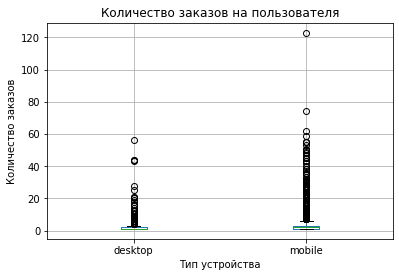

In [77]:
user_orders.boxplot(
    column='orders_count',
    by='device_type_canonical'
)

plt.title('Количество заказов на пользователя')
plt.suptitle('')
plt.xlabel('Тип устройства')
plt.ylabel('Количество заказов')
plt.show()

### Время между заказами

In [78]:
# Средний интервал между заказми

user_intervals = (
    autumn_single_device[
        autumn_single_device['days_since_prev'].notna()
    ]
    .groupby(['user_id', 'device_type_canonical'])
    .agg(
        avg_days_between_orders=('days_since_prev', 'mean')
    )
    .reset_index())

In [79]:
# Статистики
user_intervals.groupby(
    'device_type_canonical'
)['avg_days_between_orders'].describe()

,count,mean,std,min,25%,50%,75%,max
device_type_canonical,,,,,,,,
desktop,893.0,31.360656,36.581231,0.0,0.000000,16.0,53.0,146.0
mobile,7056.0,25.260670,30.219725,0.0,2.851852,14.0,36.0,148.0


In [80]:
user_intervals.groupby(
    'device_type_canonical'
)['avg_days_between_orders'].mean()

device_type_canonical
desktop    31.360656
mobile     25.260670
Name: avg_days_between_orders, dtype: float64

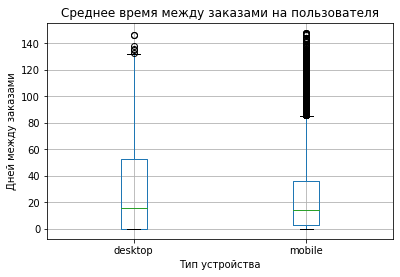

In [81]:
user_intervals.boxplot(
    column='avg_days_between_orders',
    by='device_type_canonical'
)

plt.title('Среднее время между заказами на пользователя')
plt.suptitle('')
plt.xlabel('Тип устройства')
plt.ylabel('Дней между заказами')
plt.show()

#### Промежуточный вывод по изучению данных

У пользователей мобильных устройств среднее количество заказов за осенний период выше, чем у пользователей стационарных устройств: **2,86 против 1,97 заказа на пользователя**. При этом распределения имеют правую асимметрию и содержат выбросы: у мобильных пользователей максимальное значение достигает 123 заказов, у desktop — 56.

Среднее время между заказами, наоборот, оказалось выше у пользователей стационарных устройств: **31,36 дня против 25,26 дня** у мобильных. Распределения также имеют выраженную асимметрию и выбросы.

**Обоснование выбора статистического теста**

В обоих случаях мы сравниваем средние значения двух независимых групп пользователей: mobile и desktop.

Распределения показателей имеют асимметрию и выбросы, а размеры групп существенно различаются. Поэтому для сравнения средних целесообразно использовать **односторонний t-критерий Уэлча**. Он не требует предположения о равенстве дисперсий двух групп и подходит для сравнения средних независимых выборок.

### Формирование гипотез

Уровень значимости примем α = 0,05.

#### Гипотеза 1 — количество заказов

**H₀: среднее количество заказов мобильных пользователей не больше среднего количества заказов пользователей стационарных устройств.**

**H₁: среднее количество заказов мобильных пользователей больше среднего количества заказов пользователей стационарных устройств.**

То есть проверяем предположение:

mobile > desktop

#### Гипотеза 2 — время между заказами

**H₀: среднее время между заказами мобильных пользователей не больше среднего времени между заказами пользователей стационарных устройств.**

**H₁: среднее время между заказами мобильных пользователей больше среднего времени между заказами пользователей стационарных устройств.**

То есть также проверяем:

mobile > desktop

### Проверка статистических гипотез

In [82]:
# для первого теста сравним среднее количество заказов на пользователя

alpha = 0.05

mobile_orders = user_orders.loc[
    user_orders['device_type_canonical'] == 'mobile',
    'orders_count'
]

desktop_orders = user_orders.loc[
    user_orders['device_type_canonical'] == 'desktop',
    'orders_count'
]

t_stat_orders, p_value_orders = ttest_ind(
    mobile_orders,
    desktop_orders,
    equal_var=False,
    alternative='greater'
)

print('Гипотеза 1: среднее количество заказов мобильных пользователей выше')
print(f'Среднее mobile: {mobile_orders.mean():.2f}')
print(f'Среднее desktop: {desktop_orders.mean():.2f}')
print(f't-статистика: {t_stat_orders:.4f}')
print(f'p-value: {p_value_orders:.4f}')

if p_value_orders < alpha:
    print('Результат: отвергаем H₀.')
    print('Среднее количество заказов мобильных пользователей статистически значимо выше.')
else:
    print('Результат: не отвергаем H₀.')
    print('Статистически значимых оснований считать количество заказов мобильных пользователей выше нет.')

Гипотеза 1: среднее количество заказов мобильных пользователей выше
Среднее mobile: 2.86
Среднее desktop: 1.97
t-статистика: 10.3281
p-value: 0.0000
Результат: отвергаем H₀.
Среднее количество заказов мобильных пользователей статистически значимо выше.


In [83]:
# Проверка второй гипотезы
mobile_intervals = user_intervals.loc[
    user_intervals['device_type_canonical'] == 'mobile',
    'avg_days_between_orders'
]

desktop_intervals = user_intervals.loc[
    user_intervals['device_type_canonical'] == 'desktop',
    'avg_days_between_orders'
]

t_stat_intervals, p_value_intervals = ttest_ind(
    mobile_intervals,
    desktop_intervals,
    equal_var=False,
    alternative='greater'
)

print('Гипотеза 2: среднее время между заказами мобильных пользователей выше')
print(f'Среднее mobile: {mobile_intervals.mean():.2f} дня')
print(f'Среднее desktop: {desktop_intervals.mean():.2f} дня')
print(f't-статистика: {t_stat_intervals:.4f}')
print(f'p-value: {p_value_intervals:.4f}')

if p_value_intervals < alpha:
    print('Результат: отвергаем H₀.')
    print('Среднее время между заказами мобильных пользователей статистически значимо выше.')
else:
    print('Результат: не отвергаем H₀.')
    print('Статистически значимых оснований считать время между заказами мобильных пользователей выше нет.')

Гипотеза 2: среднее время между заказами мобильных пользователей выше
Среднее mobile: 25.26 дня
Среднее desktop: 31.36 дня
t-статистика: -4.7809
p-value: 1.0000
Результат: не отвергаем H₀.
Статистически значимых оснований считать время между заказами мобильных пользователей выше нет.


In [84]:
# Сортируем все заказы пользователя по времени
orders_for_check = orders_clean.sort_values(
    ['user_id', 'created_ts_msk']
).copy()

# Дата предыдущего заказа пользователя
orders_for_check['prev_order_dt'] = (
    orders_for_check
    .groupby('user_id')['created_dt_msk']
    .shift(1)
)

# Оставляем только осенние заказы
autumn_check = orders_for_check[
    orders_for_check['season'] == 'осень'
].copy()

# Оставляем заказы, у которых предыдущий заказ был
# и произошёл до осени
autumn_prev_summer = autumn_check[
    autumn_check['prev_order_dt'].notna() &
    (autumn_check['prev_order_dt'] < pd.Timestamp('2024-09-01'))
].copy()

print('Осенних заказов с предыдущим заказом до осени:',
      len(autumn_prev_summer))

print('Из них предыдущий заказ был в августе:',
      (autumn_prev_summer['prev_order_dt'].dt.month == 8).sum())

august_cases = autumn_prev_summer[
    autumn_prev_summer['prev_order_dt'].dt.month == 8
][[
    'user_id',
    'prev_order_dt',
    'created_dt_msk',
    'days_since_prev',
    'device_type_canonical',
    'order_id'
]].sort_values('created_dt_msk')

august_users = august_cases['user_id'].nunique()

print('Пользователей с переходом август → сентябрь:', august_users)

print(
    'Mobile:',
    august_cases.loc[
        august_cases['device_type_canonical'] == 'mobile',
        'user_id'
    ].nunique()
)

print(
    'Desktop:',
    august_cases.loc[
        august_cases['device_type_canonical'] == 'desktop',
        'user_id'
    ].nunique()
)

Осенних заказов с предыдущим заказом до осени: 7419
Из них предыдущий заказ был в августе: 4735
Пользователей с переходом август → сентябрь: 4735
Mobile: 3942
Desktop: 793


#### Проверка корректности расчёта интервала между заказами

При проверке показателя `days_since_prev` было замечено, что для части первых осенних заказов предыдущий заказ пользователя мог относиться к летнему периоду. В частности, было выявлено 4 735 пользователей, у которых предыдущий заказ был совершен в августе, а следующий — уже в сентябре.

Чтобы проверить устойчивость результатов и исключить влияние перехода между сезонами, средний интервал между заказами был дополнительно рассчитан только для последовательных заказов, совершённых внутри осеннего периода (сентябрь–октябрь 2024 года). Полученные результаты использованы для итоговой проверки второй гипотезы.

In [85]:
# Проверка устойчивости результата:
# пересчитываем интервал только между заказами внутри осеннего периода

autumn_sorted = autumn_single_device.sort_values(
    ['user_id', 'created_ts_msk']
).copy()

autumn_sorted['days_between_autumn_orders'] = (
    autumn_sorted
    .groupby('user_id')['created_dt_msk']
    .diff()
    .dt.days
)

# Средний интервал между осенними заказами для каждого пользователя
autumn_intervals = (
    autumn_sorted[autumn_sorted['days_between_autumn_orders'].notna()]
    .groupby(['user_id', 'device_type_canonical'])
    .agg(
        avg_days_between_orders=('days_between_autumn_orders', 'mean')
    )
    .reset_index()
)

mobile_intervals_new = autumn_intervals.loc[
    autumn_intervals['device_type_canonical'] == 'mobile',
    'avg_days_between_orders'
]

desktop_intervals_new = autumn_intervals.loc[
    autumn_intervals['device_type_canonical'] == 'desktop',
    'avg_days_between_orders'
]

# Проверяем гипотезу H1: средний интервал у mobile больше, чем у desktop
t_stat_new, p_value_new = ttest_ind(
    mobile_intervals_new,
    desktop_intervals_new,
    equal_var=False,
    alternative='greater'
)

print('Средний интервал между осенними заказами:')
print(f'Mobile: {mobile_intervals_new.mean():.2f} дня')
print(f'Desktop: {desktop_intervals_new.mean():.2f} дня')
print(f't-статистика: {t_stat_new:.4f}')
print(f'p-value: {p_value_new:.4f}')

if p_value_new < 0.05:
    print('Отвергаем H0: средний интервал у mobile статистически больше.')
else:
    print('Не отвергаем H0: статистических оснований считать интервал у mobile больше нет.')

Средний интервал между осенними заказами:
Mobile: 6.68 дня
Desktop: 3.96 дня
t-статистика: 6.9448
p-value: 0.0000
Отвергаем H0: средний интервал у mobile статистически больше.


### Промежуточный вывод 

В ходе статистического анализа были проверены две гипотезы об активности пользователей мобильных и стационарных устройств в осенний период.

По первой гипотезе среднее количество заказов на одного пользователя мобильных устройств составило 2,86, а пользователей стационарных устройств — 1,97. Односторонний t-критерий Уэлча дал значение статистики 10,3281 и `p-value < 0,001`. Поскольку p-`value < 0,05`, нулевая гипотеза была отвергнута. Таким образом, получены статистически значимые основания считать, что **пользователи мобильных устройств в среднем совершают больше заказов, чем пользователи стационарных устройств**.

Для проверки второй гипотезы был дополнительно пересчитан интервал между заказами. Это было сделано после проверки исходного показателя `days_since_prev`, поскольку для части первых осенних заказов предыдущий заказ относился к августу. В новом расчёте учитывались только последовательные заказы, совершённые внутри осеннего периода.

Средний интервал между осенними заказами составил **6,68 дня у мобильных пользователей** и **3,96 дня у пользователей стационарных устройств**. Односторонний t-критерий Уэлча показал статистически значимое различие (`t = 6,9448`, `p-value < 0,001`). Нулевая гипотеза отвергается. Следовательно, мобильные пользователи в среднем имеют больший интервал между повторными заказами в осенний период.

Таким образом, обе исходные гипотезы получили статистически значимое подтверждение: мобильные пользователи совершают больше заказов в среднем, а интервал между их повторными заказами внутри осеннего периода также больше.

## Общий вывод и рекомендации

В ходе проекта был проведён анализ данных о заказах билетов за период **с 1 июня по 31 октября 2024 года**. После предобработки для анализа использовались данные о **287 932 заказах** пользователей мобильных и стационарных устройств. Были проверены качество данных, пропуски, дубликаты, выбросы, категории, валюты и рассчитана выручка в рублях. Дополнительно были созданы признаки месяца, сезона и стоимости одного билета.

Основные результаты анализа показали, что **осенью количество заказов заметно выше, чем летом**: на осень пришлось 58,56% всех заказов против 41,44% летом. При этом в течение рассматриваемого периода наблюдался устойчивый рост активности — от 34,3 тыс. заказов в июне до 99,3 тыс. в октябре. Среди типов мероприятий осенью наиболее востребованными оставались **концерты и театр**, а доля спортивных мероприятий заметно увеличилась по сравнению с летом. Доля театральных мероприятий также выросла, тогда как доля концертов и категории «другое» снизилась.

**Средняя стоимость одного билета осенью изменилась неодинаково в зависимости от типа мероприятия.** Рост наблюдался для выставок (+4,85%) и стендапа (+5,77%). Наиболее заметное снижение средней стоимости одного билета произошло для театра (−17,82%), ёлок (−15,42%) и концертов (−12,02%).

Анализ пользовательской активности показал наличие **выраженной недельной цикличности**: в будние дни пользователи в среднем совершают больше заказов, чем в выходные. При этом в выходные средняя стоимость одного билета выше — 195,08 руб. против 178,44 руб. в будни. На протяжении сентября и октября также наблюдались отдельные всплески заказов и пользовательской активности, поэтому при планировании продаж стоит учитывать не только сезонность, но и динамику по дням недели.

Среди регионов и партнёров наблюдаются явные лидеры. **Каменевский регион** занимает первое место по числу уникальных мероприятий, количеству заказов и выручке: на него приходится 27,69% заказов и 34,98% выручки. Среди партнёров по количеству заказов лидирует **«Билеты без проблем»** — 19,21% заказов. По выручке лидер также «Билеты без проблем» (14,82%), однако значительную долю выручки формируют также **«Мой билет» (13,27%), «Облачко» (12,98%), «Лови билет!» (12,69%) и «Весь в билетах» (11,40%)**.

### Результаты проверки гипотез

В статистической части были проверены две гипотезы об активности пользователей мобильных и стационарных устройств.

Первая гипотеза **подтвердилась**: среднее количество заказов у мобильных пользователей составило 2,86 против 1,97 у пользователей стационарных устройств. Односторонний t-критерий Уэлча показал статистически значимое различие (`p-value < 0,001`).

Вторая гипотеза также **подтвердилась**: средний интервал между последовательными заказами внутри осеннего периода составил **6,68 дня у мобильных пользователей** и **3,96 дня у пользователей стационарных устройств**. Различие статистически значимо (`t = 6,9448`, `p-value < 0,001`).

Таким образом, обе гипотезы получили статистически значимое подтверждение. Мобильные пользователи в среднем совершают больше заказов, при этом между их повторными заказами проходит больше времени.

### Рекомендации

1. **Уделить особое внимание мобильной аудитории**, поскольку мобильные пользователи в среднем совершают больше заказов. При этом более длительный интервал между повторными покупками показывает возможность дополнительно работать с удержанием пользователей: использовать напоминания, персональные рекомендации и предложения для повторного посещения.

2. **Учитывать сезонность и недельную динамику** при планировании рекламных кампаний и продаж: осенью активность значительно выше, а в будние дни количество заказов больше, чем в выходные.

3. **Отдельно анализировать регионы-лидеры**, прежде всего Каменевский регион, Североярскую область и другие территории с высокой выручкой. При этом стоит обращать внимание не только на количество заказов, но и на среднюю стоимость билетов.

4. **Контролировать изменения стоимости билетов по типам мероприятий.** Особенно интересны категории, где одновременно меняются спрос и средняя стоимость одного билета, например театр, концерты и спорт.

5. **Развивать сотрудничество с наиболее результативными партнёрами**, ориентируясь одновременно на количество заказов и выручку, поскольку лидер по объёму заказов не всегда является лидером по финансовому результату.